## Exercício

Considere $X \sim \mathrm{Binomial}(n,p)$. Gere uma amostra de tamanho $M$ pra cada item

1. Implemente a simulação de $X$ pelo método ingênuo, escrevendo $X$ como soma de $n$ variáveis aleatórias independentes com distribuição $\mathrm{Bernoulli}(p)$.

2. Implemente o método recursivo visto em sala:

   * Gere $U \sim U(0,1)$.

   * Inicialize $i=0$, $p_i=(1-p)^n$ e $F=p_i$.

   * Enquanto $U>F$, faça

     $$
     p_{i+1}=
     \frac{n-i}{i+1}
     \frac{p}{1-p}
     p_i,
     $$

     e atualize $i \leftarrow i+1$ e $F \leftarrow F+p_i$.

   * Retorne $X=i$.

3. Use a função `np.linspace` para reproduzir os passos anteriores para diferentes valores de $p$ e $n$, compare o tempo de execução dos dois métodos. Para cada valor de $p$ e $n$, execute cada método 100 vezes e calcule a média dos tempos. Utilize `time.time()` para medir o tempo de execução de cada método.

4. Apresente os resultados em uma tabela ou gráfico e comente como o tempo de execução dos métodos varia com $p$.


(array([2.000e+00, 6.800e+01, 2.590e+02, 1.240e+03, 1.768e+03, 3.320e+03,
        2.366e+03, 6.510e+02, 3.010e+02, 2.500e+01]),
 array([11. , 13.6, 16.2, 18.8, 21.4, 24. , 26.6, 29.2, 31.8, 34.4, 37. ]),
 <BarContainer object of 10 artists>)

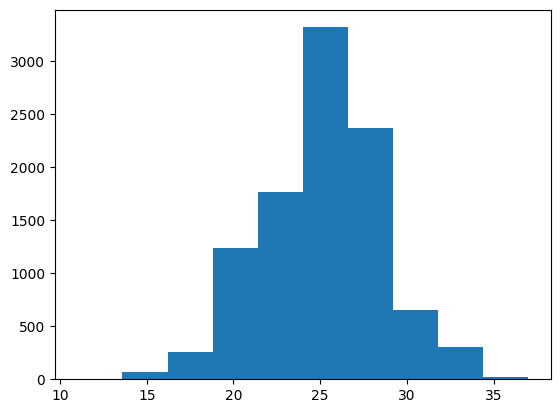

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time as time
import tqdm as tqdm # Barra de progresso de execução
#from matplotlib.widgets import Button, Slider # não funcionou
from ipywidgets import interact
import ipywidgets as iw
import pandas as pd

M = 10000

# X ~ Binomial(n, p)
def binomialIngenua(n, p):
    u = np.random.uniform(0, 1, size=n) # retorna um array de valores

    return np.sum(p >= u)

# Versão retornando amostras de binomial
def amostraBinomialIngenua(n, M, p):
    amostra = []
    for i in range(M):
        uniforme = np.random.uniform(0, 1, size=n) # retorna um array de valores
        binomial = np.sum(uniforme < p)
        amostra.append(binomial)
    return amostra

plt.hist(amostraBinomialIngenua(50, M, 0.5))

(array([  12.,  150.,  435., 1797., 2022., 3160., 1826.,  433.,  152.,
          13.]),
 array([12. , 14.6, 17.2, 19.8, 22.4, 25. , 27.6, 30.2, 32.8, 35.4, 38. ]),
 <BarContainer object of 10 artists>)

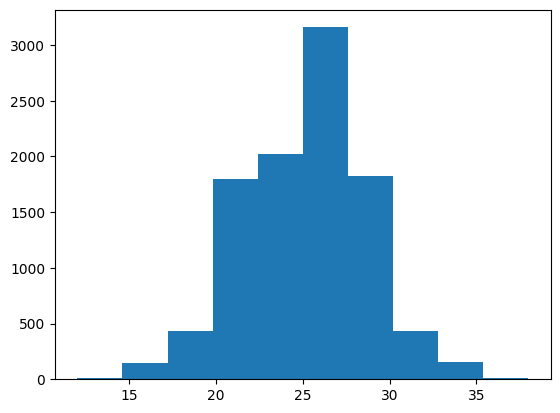

In [ ]:
# Implementação recursiva:
def binomialRecursiva(n, p):
    u = np.random.uniform(0, 1)

    i = 0
    pi = (1 - p)**n
    F = pi

    while u > F:
      pi = ((n - i)/(i + 1)) * (p/(1-p)) * pi
      i += 1
      F += pi
    return i

# Geração de amostras:
def amostraBinomialRecursiva(n, M, p):
  amostras = []
  for i in range(M):
    amostras.append(binomialRecursiva(n, p))
  return amostras


amostras = amostraBinomialRecursiva(50, M, 0.5)

plt.hist(amostras)

In [ ]:
valores_p = np.linspace(0, 0.99, num = 50) # Isso distribui uniformemente n valores do intervalo 0 - 0.99 (Ir até 1 causa uma divisão por 0)
valores_n = np.linspace(10, 50, num = 10, dtype=int) # Vários valores n para testar em conjunto com os p's
repeticoes = 20 # Repetições por valor p para cada método (recursivo e ingênuo) # 100 é muito?
runtimes_ingenuo = []
runtimes_recursivo = []
resultados = []
M = 1000 # 10000 é o original

# Iteração na listas de valores p
for p in valores_p:
  for n in valores_n:
    for i in range(repeticoes):
      # Tempos de execução do método ingênuo
      comeco = time.time()
      amostraBinomialIngenua(n, M, p)
      runtimes_ingenuo.append(time.time() - comeco)

      # Tempos de execução do método recursivo
      comeco = time.time()
      amostraBinomialRecursiva(n, M, p)
      runtimes_recursivo.append(time.time() - comeco)

    media_runtimes_ingenuo = np.mean(runtimes_ingenuo)
    media_runtimes_recursivo = np.mean(runtimes_recursivo)
    resultados.append({
        "Valor p": p,
        "Valor n": n,
        "Media Ingenuo": media_runtimes_ingenuo,
        "Media Recursivo": media_runtimes_recursivo
    })

    runtimes_ingenuo = [] # limpa os runtimes para a próxima iteração
    runtimes_recursivo = []

df_resultados = pd.DataFrame(resultados) # usando o df do pandas para não ter que desempacotar o array resultados

# Versão 1 -> Um gráfico só com tudo encapsulado (valores n e p em uma linha só)
"""
fig, ax = plt.subplots()
ax.plot('Valor p', "Media Ingenuo", label="Método Ingênuo", alpha=0.7, data=df_resultados)
ax.plot('Valor p', "Media Recursivo", label="Método Recursivo", alpha=0.7,  data=df_resultados)
ax.legend()
ax.set(xlabel="Valor p", ylabel="Runtime (ms)", title="Runtime X p")
plt.show()
"""

# TODO: slider para n no gráfico
def iwPlot(selected_n):
  df_filtrado = df_resultados[df_resultados["Valor n"] == selected_n]

  fig, ax = plt.subplots()
  ax.plot('Valor p', "Media Ingenuo", label="Método Ingênuo", alpha=0.7, data=df_filtrado)
  ax.plot('Valor p', "Media Recursivo", label="Método Recursivo", alpha=0.7,  data=df_filtrado)

  ax.legend()
  ax.set(xlabel="Valor p", ylabel="Runtime (ms)", title="Runtime X p")
  plt.show()

interact(
    iwPlot,
    selected_n=iw.SelectionSlider(
        options=valores_n,
        value=valores_n[0],
        description='Valor n:',
        disabled=False,
        continuous_update=False
    )
)

#print(resultados)


interactive(children=(SelectionSlider(continuous_update=False, description='Valor n:', options=(np.int64(10), …

<function __main__.iwPlot(selected_n)>